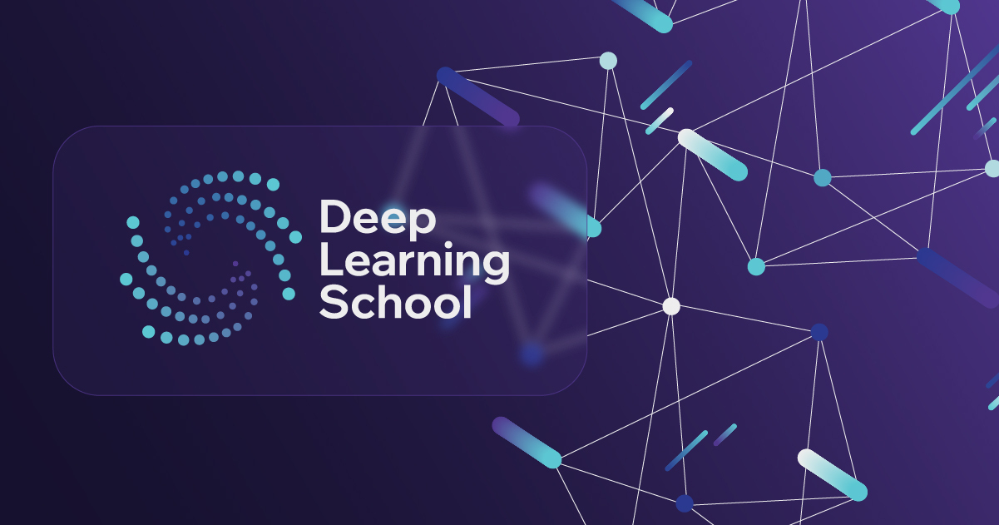


<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

# Домашнее задание. RAG.

В этом домашнем задании вам предстоит создать туристический RAG, провести EDA и проявить креатив! :)

Вам дан набор данных, содержащий информацию о памятниках, архитектуре и других значимых местах. В данных есть:
* название достопримечательности;
* идентификатор на WikiData;
* город расположения;
* координаты долготы и широты;
* описание (извлеченное из WikiData);
* изображение в формате base64;
* сгенерированное описание изображения (генерация с помощью модели BLIP).

Некоторые из памятников могут встречаться несколько раз, но с различными изображениями, из которых не все могут быть качественными. Для компенсации этого даны текстовые описания.

Часть данных взята с Национальной технологической олимпиады студентов по CV. Базовое решение предполагает использование мультимодального ru-CLIP. Но в данном домашнем задании предлагается решить эту задачу творчески, используя NLP подход.

## Установка и импорт библиотек

In [ ]:
!pip install -q --no-cache-dir \
    torch==2.10.0 \
    torchvision==0.25.0 \
    --index-url https://download.pytorch.org/whl/cu130

In [ ]:
!pip install -q gdown transformers accelerate bitsandbytes langchain sentence-transformers openpyxl datasets langchain-community umap-learn langchain-classic pylate

In [ ]:
!pip install -q --upgrade \
    requests==2.32.4 \
    cuda-bindings==13.0.3

In [ ]:
!pip install -q langchain-qdrant qdrant-client

In [ ]:
import gdown
import pandas as pd
from tqdm.notebook import tqdm
from typing import Optional, List, Tuple
import matplotlib.pyplot as plt
from langchain_core.documents import Document as LangchainDocument
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer
from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.vectorstores.utils import DistanceStrategy
import numpy as np
import plotly.express as px
from transformers import pipeline
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from pylate import models, rank

#------------------------------------------------------------------------------------
# from langchain.text_splitter import ... # выберите другую стратегию разбивки на чанки

# pd.set_option("display.max_colwidth", None)

/tmp/ipykernel_214/692993772.py:11: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.embeddings import HuggingFaceEmbeddings


## Загрузка данных (4 балла)

In [ ]:
url = 'https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk'
output = 'file.csv'

gdown.download(url, output, quiet=False)

data = pd.read_csv('file.csv')

Downloading...
From (original): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk
From (redirected): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk&confirm=t&uuid=8fe6843f-5109-4312-9d4d-e12ce3f5ebe5
To: /content/file.csv
100%|██████████| 672M/672M [00:07<00:00, 87.8MB/s]


In [ ]:
data.head()

,Unnamed: 0,Name,WikiData,City,Lon,Lat,description,image,en_txt
0,0,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there are two people that are standing on a tr...
1,1,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed building with a blue and white exterior...
2,2,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
3,3,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
4,4,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a boat that is in the water near a bu...


In [ ]:
data.drop(columns=['Unnamed: 0'], inplace=True)

In [ ]:
data.head()

,Name,WikiData,City,Lon,Lat,description,image,en_txt
0,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there are two people that are standing on a tr...
1,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed building with a blue and white exterior...
2,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
3,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
4,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a boat that is in the water near a bu...


Для декодирования изображений, закодированных в формате base64, можно использовать следующий код:

In [ ]:
import base64
import requests
import matplotlib.pyplot as plt
from PIL import Image
import PIL
from io import BytesIO

In [ ]:
def get_image(data):
  image = Image.open(BytesIO(base64.b64decode(data))).convert('RGB')
  return image

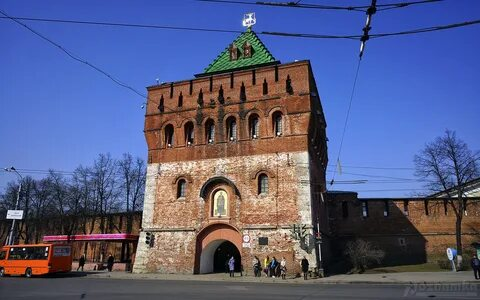

In [ ]:
get_image(data.sample(1)['image'].tolist()[0])

В данных есть выбросы — записи, не относящихся к туристическим или историческим объектам. Для очистки данных можно, например, использовать алгоритм TF-IDF: создаем корпус текстов из описаний, применяем TF-IDF, извлекаем наиболее редко или часто встречающиеся слова. Они могут указывать на мусорные данные, такие как мемы, баннеры или личные фото людей. После выделения подозрительных паттернов, можно провести ручную проверку и фильтрацию данных.

Для дальнейшего тестирования и получения чистых сэмплов, рекомендуется взять не менее 100 чистых образцов со стратификацией по городу и названию места. Это можно сделать, выбрав случайным образом несколько образцов из каждой категории (город + название места), чтобы обеспечить равномерное представительство и разнообразие данных.

**!! Важно:** Помните, что чистые сэмплы одного и того же места выдадут примерно одинаковое описание. Есть несколько стратегий, как повысить разнообразие ответов:

- выбор одного самого лучшего:
  - самое длинное описание
  - смое подходящие по мнению LLM
- конкатенация описаний (но важно не сконкатенировать слишком много)

Изображения можно отдать в мета-данные.

Применим алгоритм TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(
    stop_words='english'
)

In [ ]:
corpus = data['en_txt'].to_list()

In [ ]:
X = vectorizer.fit_transform(corpus)

In [ ]:
feature_names = vectorizer.get_feature_names_out()

In [ ]:
k = 30

In [ ]:
max_idf_ind = np.argsort(vectorizer.idf_)[-k:]

In [ ]:
feature_names[max_idf_ind]

array(['lighting', 'mansion', 'mantisce', 'mark', 'magazine', 'live',
       'lizard', 'lilies', 'lily', 'letter', 'lettering', 'letters',
       'ladders', 'laid', 'llama', 'llamas', 'listening', 'land',
       'landing', 'languages', 'lantern', 'laboratory', 'wrestling',
       'zazne', 'worker', '100th', 'прррмомоннннннннннн', 'сралнннннн',
       'yevava', 'wrong'], dtype=object)

In [ ]:
possible_noise = ['прррмомоннннннннннн', 'сралнннннн', 'zazne', 'yevava']

In [ ]:
for index, text in enumerate(corpus):
    for word in possible_noise:
        if word in text:
            print(f"{index} {word} in `{text}`")

2660 yevava in `there is a plaque on the wall of a building that reads yevava`
5609 zazne in `arafiski - zazne - cultural - building - in - the - 1930s -`
9958 сралнннннн in `сралнннннн - cerque apttapa album`
14353 прррмомоннннннннннн in `прррмомоннннннннннн`


In [ ]:
possible_noise_ind = [9958, 14353]

                              Name  WikiData       City                  description               en_txt
14353  Ярославский дворец молодёжи  Q4538877  Ярославль  Ярославский дворец молодёжи  прррмомоннннннннннн


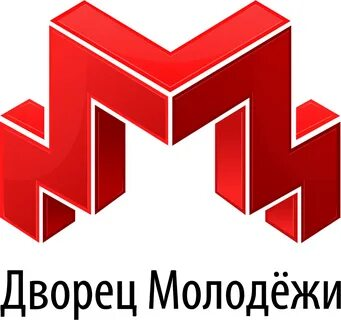

        Name WikiData      City description                             en_txt
9958  Сердце      NaN  Владимир         NaN  сралнннннн - cerque apttapa album


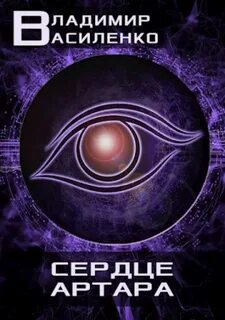

             Name   WikiData             City                                         description                                                       en_txt
5609  Дом Советов  Q28032873  Нижний Новгород  административное здание в Нижнем Новгороде, Россия  arafiski - zazne - cultural - building - in - the - 1930s -


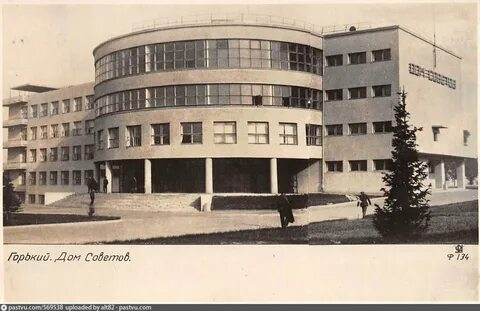

                   Name  WikiData          City        description                                                         en_txt
2660  Усадьба Железнова  Q4477566  Екатеринбург  Усадьба Железнова  there is a plaque on the wall of a building that reads yevava


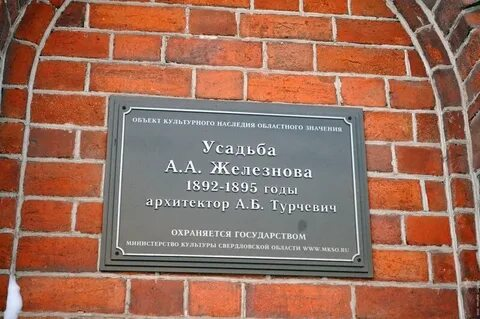

In [ ]:
for word in possible_noise:
    print(data[data['en_txt'].str.contains(word)][['Name', 'WikiData', 'City', 'description', 'en_txt']].to_string())
    display(get_image(data[data['en_txt'].str.contains(word)]['image'].tolist()[0]))

In [ ]:
data.iloc[possible_noise_ind]

,Name,WikiData,City,Lon,Lat,description,image,en_txt
9958,Сердце,NaN,Владимир,40.410282,56.12999,NaN,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,сралнннннн - cerque apttapa album
14353,Ярославский дворец молодёжи,Q4538877,Ярославль,39.867222,57.63625,Ярославский дворец молодёжи,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,прррмомоннннннннннн


In [ ]:
data.drop(possible_noise_ind, inplace=True)

In [ ]:
feature_names[np.argsort(vectorizer.idf_)[:k]]

array(['building', 'arafed', 'view', 'large', 'white', 'clock', 'church',
       'tower', 'green', 'man', 'roof', 'statue', 'dome', 'people',
       'steeple', 'standing', 'park', 'city', 'street', 'domes', 'brick',
       'red', 'parked', 'lot', 'room', 'sign', 'blue', 'cars',
       'background', 'photo'], dtype=object)

Удалим артефакт `arafed`

In [ ]:
data['en_txt'] = data['en_txt'].str.replace('arafed', '')

Снова применим алгоритм TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer2 = TfidfVectorizer(
    stop_words='english'
)

In [ ]:
corpus2 = data['en_txt'].to_list()

In [ ]:
X = vectorizer2.fit_transform(corpus2)

In [ ]:
feature_names2 = vectorizer2.get_feature_names_out()

In [ ]:
feature_names2[np.argsort(vectorizer2.idf_)[:k]]

array(['building', 'view', 'large', 'white', 'clock', 'church', 'tower',
       'green', 'man', 'roof', 'statue', 'dome', 'people', 'steeple',
       'standing', 'park', 'city', 'street', 'domes', 'brick', 'red',
       'parked', 'lot', 'room', 'sign', 'blue', 'cars', 'background',
       'photo', 'golden'], dtype=object)

Посмотрим на изображения, где имя == Сердце

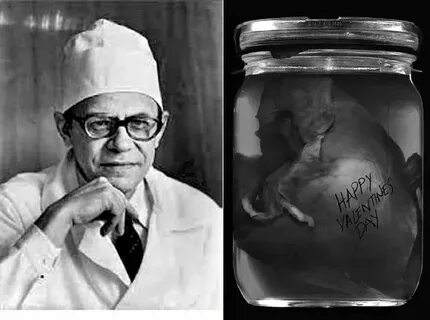

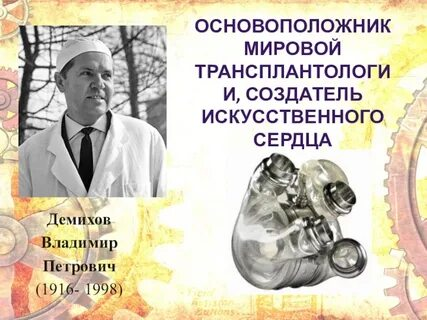

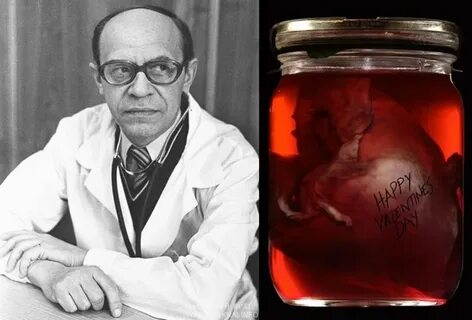

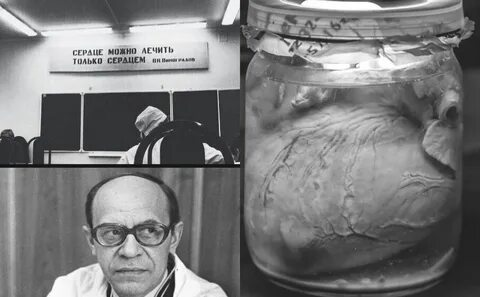

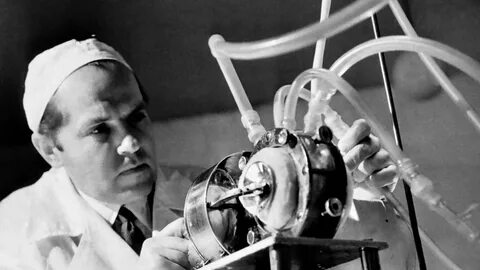

...

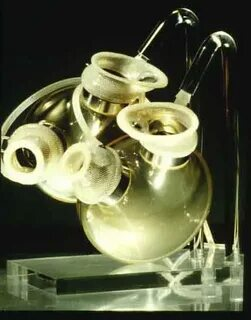

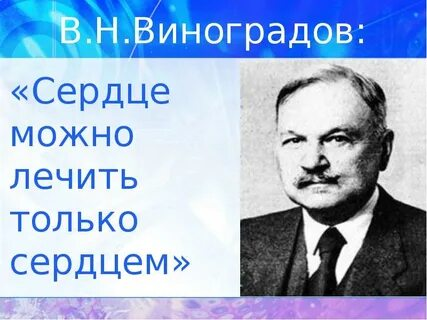

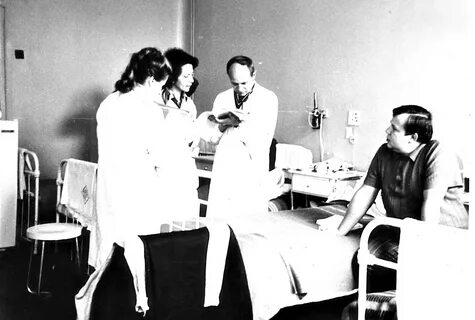

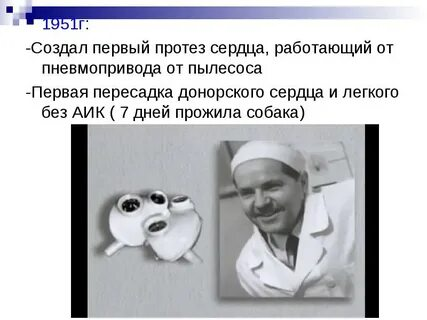

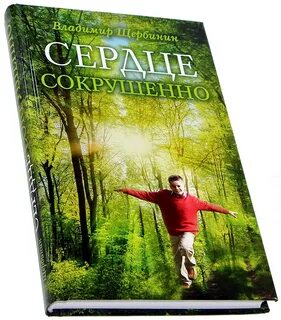

In [ ]:
for image in data[data['Name'] == 'Сердце']['image'].to_list():
    display(get_image(image))

Видно, что это мусор, поэтому удалим его

In [ ]:
data.drop(data[data['Name'] == 'Сердце']['image'].index, inplace=True)

Посмотрим на дубликаты, у которых не совпадают только координаты (это может быть просто погрешность), а остальное одинаковое

In [ ]:
data.duplicated(data.columns.difference(['Lon', 'Lat'])).sum()

np.int64(265)

In [ ]:
data[data.duplicated(data.columns.difference(['Lon', 'Lat']))]

,Name,WikiData,City,Lon,Lat,description,image,en_txt
2378,улица Февральской Революции,Q4474328,Екатеринбург,60.593147,56.841328,улица в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,an old photo of a house with a lot of windows
2380,улица Февральской Революции,Q4474328,Екатеринбург,60.593147,56.841328,улица в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,building with a clock on the front of it
2382,улица Февральской Революции,Q4474328,Екатеринбург,60.593147,56.841328,улица в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,wooden house with a metal roof and a fence
2384,улица Февральской Революции,Q4474328,Екатеринбург,60.593147,56.841328,улица в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,an old photo of a run down house with a lot of...
2386,улица Февральской Революции,Q4474328,Екатеринбург,60.593147,56.841328,улица в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,an old photo of a building with a clock tower ...
...,...,...,...,...,...,...,...,...
8593,Владимир,NaN,Владимир,40.367638,56.152447,NaN,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a statue of a man on a horse in a park
8595,Владимир,NaN,Владимир,40.361938,56.158051,NaN,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,view of a city with a church and a clock tower
8596,Владимир,NaN,Владимир,40.367638,56.152447,NaN,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,view of a city with a church and a clock tower
8598,Владимир,NaN,Владимир,40.361938,56.158051,NaN,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,a large white building with gold domes in a park


Удалим данные дубликаты

In [ ]:
data.drop(data[data.duplicated(data.columns.difference(['Lon', 'Lat']))].index, inplace=True)

Посмотрим на уникальные имена

In [ ]:
data['Name'].unique()

array(['Динамо', '№32 Дом обороны', 'Дом обороны',
       '№28 Здание городской электростанции «Луч»',
       '№27 Дом Г.Н. Скрябина', 'Литературная жизнь Урала XX века',
       'Дом-музей Бажова', 'Театр кукол', 'Харитоновский сад',
       'Храм в честь Вознесения Господня', 'Суворовское училище',
       'Свято-Троицкий Кафедральный собор',
       'Дом-музей Д. Н. Мамина-Сибиряка',
       'Художественный Музей Эрнста Неизвестного', 'Серго Орджоникидзе',
       'Н. И. Кузнецову', 'Успенский собор на ВИЗе', 'Царский мост',
       'Дом печати (Екатеринбург)', 'Музей изобразительных искусств',
       'Александро-Невский собор', 'Здание бывшей гостиницы "Мадрид"',
       'Екатеринбургский музей изобразительных искусств',
       'Уральский государственный медицинский университет',
       'Центральный стадион', 'Уральская государственная консерватория',
       '№18 Фотографический музей «Дом Метенкова»',
       'Преображенская церковь на Уктусе',
       'Уральский геологический музей', 'Дом 

Выделим подозрительные - спортивные стадионы, странные названия, улицы.

In [ ]:
possible_wrong = ['Динамо', 'Комсомолу Урала', 'Ленин', 'улица Февральской Революции',
                  'улица Чернышевского', 'улица Добролюбова', 'Рекорд', 'Локомотив',
                  'église arménienne de Vladimir', 'Концертно-спортивный комплекс Art Hall',
                  'Дружба', 'Старый Владимир', 'Огни Владимира', 'Владимир', 'Танкистам',
                  '1941-1945', 'Бобёр', 'Кино 9D', 'Cerkiew Narodzenia Pańskiego w Jarosławiu',
                  'Cerkiew Włodzimierskiej Ikony Matki Bożej w Jarosławiu',
                  'Cerkiew św. Dymitra Sołuńskiego w Jarosławiu', ]

In [ ]:
for name in possible_wrong:
    print(name)
    print(data[data['Name'] == name][['Name', 'WikiData', 'City', 'description', 'en_txt']].to_string())
    for image in data[data['Name'] == name]['image'].to_list():
        display(get_image(image))

После ручного отбора было установлено, что следующие данные надо удалить

In [ ]:
delete_wrong = ['Динамо', 'Локомотив', 'Танкистам', '1941-1945', 'Бобёр']

In [ ]:
data.drop(data[data['Name'].isin(delete_wrong)].index, inplace=True)

Сгруппируем данные по `City` + `Name`, для каждого объекта возьмём топ-3 описания по длине и сконкаттенируем их

In [ ]:
data_group = data.groupby(['City', 'Name'])

In [ ]:
result = []

for (city, name), group in data_group:
    top_3 = (group.assign(word_count=group['en_txt'].str.split().str.len()).sort_values(by='word_count', ascending=False).head(3))

    images = top_3['image'].to_list()
    txt = '. '.join(top_3['en_txt'].to_list())
    lon = top_3.iloc[0]['Lon']
    lat = top_3.iloc[0]['Lat']
    wiki = top_3.iloc[0]['WikiData']

    result.append({
        'City': city,
        'Name': name,
        'WikiData': wiki,
        'Lon': lon,
        'Lat': lat,
        'image': images,
        'en_txt': txt
    })

new_data = pd.DataFrame(result)

In [ ]:
new_data

,City,Name,WikiData,Lon,Lat,image,en_txt
0,Владимир,2000 летию Рождества Христова,NaN,40.408882,56.127674,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,a close up of a stamp with a painting of a wom...
1,Владимир,église arménienne de Vladimir,Q18331756,40.456497,56.154667,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,a view of a large white building with a clock ...
2,Владимир,Авиамеханический колледж,Q18786015,40.387318,56.126278,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,there are many people sitting in a classroom w...
3,Владимир,Аптекарь,NaN,40.402309,56.127251,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,there is a statue of a man holding a bottle of...
4,Владимир,Белокаменные памятники Владимира и Суздаля,Q838264,40.416698,56.150002,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,a picture of a picture of a church and a pictu...
...,...,...,...,...,...,...,...
380,Ярославль,церковь Иоанна Предтечи в Толчкове,Q2084804,39.856861,57.610909,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,aerial view of a church with a green roof and ...
381,Ярославль,церковь Михаила Архангела,Q1365930,39.892590,57.622082,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,snowy scene of a church with a steeple and a s...
382,Ярославль,церковь Николая Чудотворца,Q30913942,39.870548,57.620068,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,an old picture of a large building with two to...
383,Ярославль,церковь Николы Рублёного,Q16715656,39.898258,57.622509,[/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFB...,there is a white building with two towers and ...


In [ ]:
new_data.groupby('City').count()

,Name,WikiData,Lon,Lat,image,en_txt
City,,,,,,
Владимир,93,29,93,93,93,93
Екатеринбург,96,96,96,96,96,96
Нижний Новгород,97,97,97,97,97,97
Ярославль,99,96,99,99,99,99


Из каждого города получается примерно по 100 объектов

Здесь предлагаем вам построить RAG с использованием моделей, которые не были представлены на семинаре (включая другие векторные базы данных). Можно воспользоваться материалами по этой ссылке: [data_connection/vectorstores](https://python.langchain.com/v0.1/docs/modules/data_connection/vectorstores/).

!Важно, не забудьте отранжировать чанки текстов с помощью `ragatouille`. На практике порядок текстов в промпте влияет на точность ответа.

In [ ]:
RAW_KNOWLEDGE_BASE = [
    LangchainDocument(page_content=doc.en_txt, metadata={
        "city": doc.City,
        'Name': doc.Name,
        'WikiData': doc.WikiData,
        'Lon': doc.Lon,
        'Lat': doc.Lat,
        "images": doc.image})
    for doc in tqdm(new_data.itertuples())
]

0it [00:00, ?it/s]

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

MARKDOWN_SEPARATORS = [
    "\n#{1,6} ",
    "```\n",
    "\n\\*\\*\\*+\n",
    "\n---+\n",
    "\n___+\n",
    "\n\n",
    "\n",
    " ",
    "",
]

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=400,  # Максимальное количество символов в чанке
    chunk_overlap=50,  # Количество символов, которые будут перекрываться между чанками
    add_start_index=True,  # Если "True", то включает начальный индекс чанка в метаданные
    strip_whitespace=True,  # Если значение "True", то пробелы удаляются из начала и конца каждого документа
    separators=MARKDOWN_SEPARATORS,
)

docs_processed = []
for doc in RAW_KNOWLEDGE_BASE:
    docs_processed += text_splitter.split_documents([doc])

In [ ]:
EMBEDDING_MODEL_NAME = "BAAI/bge-m3"

embedding_model = HuggingFaceEmbeddings(
    model_name=EMBEDDING_MODEL_NAME,
    multi_process=True,
    model_kwargs={"device": "cuda"},
    encode_kwargs={"normalize_embeddings": True},  # `True` для косинусного сходства
)


KNOWLEDGE_VECTOR_DATABASE = QdrantVectorStore.from_documents(
    documents=docs_processed,
    embedding=embedding_model,
    location=":memory:",
    collection_name="attractions",
)

/tmp/ipykernel_214/2712413079.py:3: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embedding_model = HuggingFaceEmbeddings(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

... (8 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Посмотрим на вывод

In [ ]:
user_query = "Which cathedrals can one visit?"
query_vector = embedding_model.embed_query(user_query)

In [ ]:
print(f"\nStarting retrieval for {user_query=}...")
retrieved_docs = KNOWLEDGE_VECTOR_DATABASE.similarity_search(
    query=user_query,
    k=10
)
print("\n==================================Top document==================================")
print(retrieved_docs[0].page_content)
print("==================================Metadata==================================")
print(retrieved_docs[0].metadata)


Starting retrieval for user_query='Which cathedrals can one visit?'...

==================================Top document==================================
view of a church with a lot of windows and a lot of scaffolding. a close up of two pictures of a church with a cross on top. people are walking around in front of a large building with golden domes
==================================Metadata==================================
{'city': 'Владимир', 'Name': 'Собор Успения Пресвятой Богородицы', 'WikiData': 'Q775487', 'Lon': 40.409214, 'Lat': 56.127438, 'images': ['...'], 'start_index': 1, '_id': '8465f8fd-d5c3-46ab-b519-b7f2f9b22fef', '_collection_name': 'attractions'}


Также посмотрим на топ-5 ответов вместе со скорами

In [ ]:
retrieved_docs_with_scores = KNOWLEDGE_VECTOR_DATABASE.similarity_search_with_score(
    query=user_query,
    k=5
)

for i, (doc, score) in enumerate(retrieved_docs_with_scores, 1):
    print(f"Результат {i}")
    print(f"Score: {score}")
    print(f"Название: {doc.metadata.get('Name')}")
    print(f"Город: {doc.metadata.get('city')}")
    print(f"Текст: {doc.page_content[:500]}")

Результат 1
Score: 0.48311348838717216
Название: Собор Успения Пресвятой Богородицы
Город: Владимир
Текст: view of a church with a lot of windows and a lot of scaffolding. a close up of two pictures of a church with a cross on top. people are walking around in front of a large building with golden domes
Результат 2
Score: 0.4703803316328455
Название: №15 Храм-на-Крови
Город: Екатеринбург
Текст: view of a church with a golden dome and a cross on the top. a close up of a building with a golden dome on top of it.  view of a church with a lot of red tulips in front of it
Результат 3
Score: 0.47033722909306913
Название: Александро-Невский собор
Город: Екатеринбург
Текст: view of a church with a large dome and a painting on the wall. an old photo of a church with a large dome and a clock tower.  view of a white church with gold domes and a clock tower
Результат 4
Score: 0.4699746203815167
Название: Успенский собор
Город: Ярославль
Текст: a view of a large white building with gold domes on to

Все ответы связаны с соборами/храмами, что хорошо

Сделаем реранкинг, но с помощью `pylate`, так как `ragatouille` плохо работает с новыми версиями

In [ ]:
RERANKER_MODEL_NAME = "lightonai/answerai-colbert-small-v1"

reranker_model = models.ColBERT(
    model_name_or_path=RERANKER_MODEL_NAME,
    device="cuda" if torch.cuda.is_available() else "cpu"
)

# Compiling the model to make the training faster
reranker_model = torch.compile(reranker_model)

modules.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/6.51k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/721 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (2 outputs left out)

tokenizer_config.json:   0%|          | 0.00/1.61k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/582 [00:00<?, ?B/s]

In [ ]:
documents = [[doc.page_content for doc in retrieved_docs]]
documents_ids = [[str(i) for i in range(len(retrieved_docs))]]
queries = [user_query]

In [ ]:
queries_embeddings = reranker_model.encode(
    queries,
    is_query=True,
)

documents_embeddings = reranker_model.encode(
    documents,
    is_query=False,
)

reranked_documents = rank.rerank(
    documents_ids=documents_ids,
    queries_embeddings=queries_embeddings,
    documents_embeddings=documents_embeddings,
)

In [ ]:
reranked_documents

[[{'id': '6', 'score': 30.536218643188477},
  {'id': '7', 'score': 30.513025283813477},
  {'id': '8', 'score': 30.473249435424805},
  {'id': '4', 'score': 30.470447540283203},
  {'id': '0', 'score': 30.469669342041016},
  {'id': '2', 'score': 30.469026565551758},
  {'id': '1', 'score': 30.462480545043945},
  {'id': '5', 'score': 30.462223052978516},
  {'id': '3', 'score': 30.44198226928711},
  {'id': '9', 'score': 30.426692962646484}]]

Посмотрим на документы

In [ ]:
for i, result in enumerate(reranked_documents[0], 1):
    doc_idx = int(result["id"])
    doc = retrieved_docs[doc_idx]

    print(f"Результат {i}")
    print(f"Score: {result['score']}")
    print(f"Название: {doc.metadata.get('Name')}")
    print(f"Город: {doc.metadata.get('city')}")
    print(f"Текст: {doc.page_content[:500]}")

Результат 1
Score: 30.536218643188477
Название: Спасо-преображенская церковь
Город: Нижний Новгород
Текст: there is a large white building with a gold spire and a clock tower.  view of a church with a clock tower and a clock on the top.  view of a church with a steeple and a lake in the foreground
Результат 2
Score: 30.513025283813477
Название: Cerkiew Włodzimierskiej Ikony Matki Bożej w Jarosławiu
Город: Ярославль
Текст: view of a church with a clock tower in the middle of the day. there is a small church with a steeple and a steeple on the side. there is a blue church with a steeple and a cross on the front
Результат 3
Score: 30.473249435424805
Название: Белокаменные памятники Владимира и Суздаля
Город: Владимир
Текст: a picture of a picture of a church and a picture of a building.  view of a large white and gold building with a clock tower.  view of a church with a flower garden in front of it
Результат 4
Score: 30.470447540283203
Название: Храм святителей Московских
Город: Нижний Н

Сформируем контекст

In [ ]:
reranked_docs = [
    retrieved_docs[int(result["id"])]
    for result in reranked_documents[0]
]

# Формируем контекст
context = "\nExtracted documents:\n"

for i, doc in enumerate(reranked_docs, 1):
    context += (
        f"\nDocument {i}:\n"
        f"Name: {doc.metadata.get('Name')}\n"
        f"City: {doc.metadata.get('city')}\n"
        f"Text: {doc.page_content}\n"
    )

In [ ]:
context

'\nExtracted documents:\n\nDocument 1:\nName: Спасо-преображенская церковь\nCity: Нижний Новгород\nText: there is a large white building with a gold spire and a clock tower.  view of a church with a clock tower and a clock on the top.  view of a church with a steeple and a lake in the foreground\n\nDocument 2:\nName: Cerkiew Włodzimierskiej Ikony Matki Bożej w Jarosławiu\nCity: Ярославль\nText: view of a church with a clock tower in the middle of the day. there is a small church with a steeple and a steeple on the side. there is a blue church with a steeple and a cross on the front\n\nDocument 3:\nName: Белокаменные памятники Владимира и Суздаля\nCity: Владимир\nText: a picture of a picture of a church and a picture of a building.  view of a large white and gold building with a clock tower.  view of a church with a flower garden in front of it\n\nDocument 4:\nName: Храм святителей Московских\nCity: Нижний Новгород\nText: view of a church with a golden dome and a white and gold roof. ye

Выберем модель `Qwen/Qwen2.5-0.5B-Instruct`

In [ ]:
from transformers import pipeline
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

READER_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
)

reader_model = AutoModelForCausalLM.from_pretrained(READER_MODEL_NAME, quantization_config=bnb_config)
tokenizer = AutoTokenizer.from_pretrained(READER_MODEL_NAME)

READER_LLM = pipeline(
    model=reader_model,
    tokenizer=tokenizer,
    task="text-generation",
    do_sample=True,
    temperature=0.2,
    repetition_penalty=1.1,
    return_full_text=False,
    max_new_tokens=1000,
)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

In [ ]:
prompt_in_chat_format = [
    {
        "role": "system",
        "content": """Using the information contained in the context,
give a comprehensive but concise answer to the question.

For each relevant location, provide:
1. Name of the attraction.
2. City where it is located.
3. A clear and natural description of the attraction.
4. Geographic coordinates (latitude and longitude), if available.

When writing descriptions:
- Rewrite the source text into natural, fluent language.
- Translate Russian names into English.
- NECESSARILY remove image-caption phrases such as "View of", "There is", "Picture of",
  "Image of", "a close up of", and similar expressions.
- Do not describe the image itself. Describe the actual attraction.
- Remove repetitive and redundant information.
- Preserve the factual details from the original description.
- Do not add details that are not supported by the context.

Do not invent or assume any information.
If some information is missing from the context, explicitly indicate that it is unavailable.
If the answer cannot be deduced from the context, do not provide an unsupported answer.
Do not confuse churches, cathedrals, monasteries, and other types of buildings.
Only claim that a location can be visited if this is explicitly confirmed by the context.""",
    },
    {
        "role": "user",
        "content": """Context:
{context}
---
Now here is the question you need to answer.

Question: {question}

Provide the answer in a structured format."""
    },
]

RAG_PROMPT_TEMPLATE = tokenizer.apply_chat_template(
    prompt_in_chat_format, tokenize=False, add_generation_prompt=True
)
print(RAG_PROMPT_TEMPLATE)

<|im_start|>system
Using the information contained in the context,
give a comprehensive but concise answer to the question.

For each relevant location, provide:
1. Name of the attraction.
2. City where it is located.
3. A clear and natural description of the attraction.
4. Geographic coordinates (latitude and longitude), if available.

When writing descriptions:
- Rewrite the source text into natural, fluent language.
- Translate Russian names into English.
- NECESSARILY remove image-caption phrases such as "View of", "There is", "Picture of",
  "Image of", "a close up of", and similar expressions.
- Do not describe the image itself. Describe the actual attraction.
- Remove repetitive and redundant information.
- Preserve the factual details from the original description.
- Do not add details that are not supported by the context.

Do not invent or assume any information.
If some information is missing from the context, explicitly indicate that it is unavailable.
If the answer cannot 

In [ ]:
final_prompt = RAG_PROMPT_TEMPLATE.format(question=user_query, context=context)

answer = READER_LLM(final_prompt)[0]["generated_text"]
print(answer)

Both `max_new_tokens` (=1000) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


1. Спасо-преображенская церкви (Nizhny Novgorod)
   City: Нижний Новгород
   Description: Large white building with a gold spire and a clock tower. View of a church with a clock tower and a clock on the top. View of a church with a steeple and a lake in the foreground.
   
2. Кремлевская княжеская церковь (Ярославль)
   City: Ярославль
   Description: Large white building with gold domes on top of it. View of a church with a large altar and a small altar. View of a golden spire on a building with a cross on top. View of a church with a steeple and a steeple on the top.
   
3. Белокаменные памятники Владимира и Суздаля (Владимир)
   City: Владимир
   Description: Picture of a picture of a church and a picture of a building. View of a large white and gold building with a clock tower. View of a church with a flower garden in front of it.
   
4. Храм святителям Московских (Нижний Новгород)
   City: Нижний Новгород
   Description: Picture of a picture of a church and a picture of a building

Попробуем ещё вопрос

In [ ]:
test_queries = [
    "What are the main attractions in Yaroslavl?"
]

In [ ]:
queries_embeddings2 = reranker_model.encode(
    test_queries,
    is_query=True,
)

reranked_documents2 = rank.rerank(
    documents_ids=documents_ids,
    queries_embeddings=queries_embeddings2,
    documents_embeddings=documents_embeddings,
)

In [ ]:
reranked_docs2 = [
    retrieved_docs[int(result["id"])]
    for result in reranked_documents2[0]
]

# Формируем контекст
context2 = "\nExtracted documents:\n"

for i, doc in enumerate(reranked_docs2):
    context2 += f"""
        Document {i}:
        Name: {doc.metadata.get('Name', 'Unknown')}
        City: {doc.metadata.get('city', 'Unknown')}
        Latitude: {doc.metadata.get('Lat', 'Unknown')}
        Longitude: {doc.metadata.get('Lon', 'Unknown')}
        Description: {doc.page_content}
        """

In [ ]:
context2

'\nExtracted documents:\n\n        Document 0:\n        Name: Спасо-преображенская церковь\n        City: Нижний Новгород\n        Latitude: 56.256714\n        Longitude: 43.933346\n        Description: there is a large white building with a gold spire and a clock tower.  view of a church with a clock tower and a clock on the top.  view of a church with a steeple and a lake in the foreground\n        \n        Document 1:\n        Name: Cerkiew Włodzimierskiej Ikony Matki Bożej w Jarosławiu\n        City: Ярославль\n        Latitude: 57.611237\n        Longitude: 39.906563\n        Description: view of a church with a clock tower in the middle of the day. there is a small church with a steeple and a steeple on the side. there is a blue church with a steeple and a cross on the front\n        \n        Document 2:\n        Name: Храм святителей Московских\n        City: Нижний Новгород\n        Latitude: 56.312874\n        Longitude: 43.997238\n        Description: view of a church with 

In [ ]:
final_prompt2 = RAG_PROMPT_TEMPLATE.format(question=test_queries, context=context2)

answer2 = READER_LLM(final_prompt2)[0]["generated_text"]
print(answer2)

Both `max_new_tokens` (=1000) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Name: Крестоборогодская церковь
City: Ярославль
Latitude: 57.578876
Longitude: 39.849354
Description: view of a large white building with gold domes and a clock tower.  view of a church with a large altar and a small altar.  image of a street with a church and a street with cars.


Получилось что-то похожее на правду

Выполните визуализацию эмбеддингов при помощи метода главных компонент (PCA) и Uniform Manifold Approximation and Projection (UMAP). Пожалуйста, выполните PCA независимо от pacmap.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [ ]:
texts = [doc.page_content for doc in docs_processed]
document_embeddings = embedding_model.embed_documents(texts)
document_embeddings = np.array(document_embeddings)

PCA

In [ ]:
pca = PCA(n_components=2)
pca_embeddings = pca.fit_transform(document_embeddings)

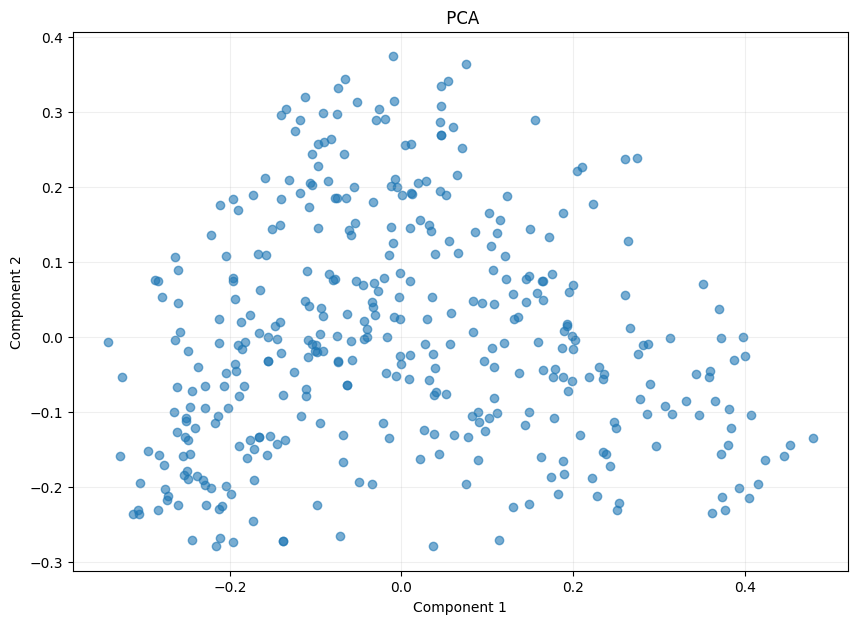

In [ ]:
plt.figure(figsize=(10, 7))
plt.scatter(
    pca_embeddings[:, 0],
    pca_embeddings[:, 1],
    alpha=0.6
)

plt.title(" PCA")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.grid(alpha=0.2)
plt.show()

UMAP

In [ ]:
import umap

umap_reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)

umap_embeddings = umap_reducer.fit_transform(document_embeddings)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


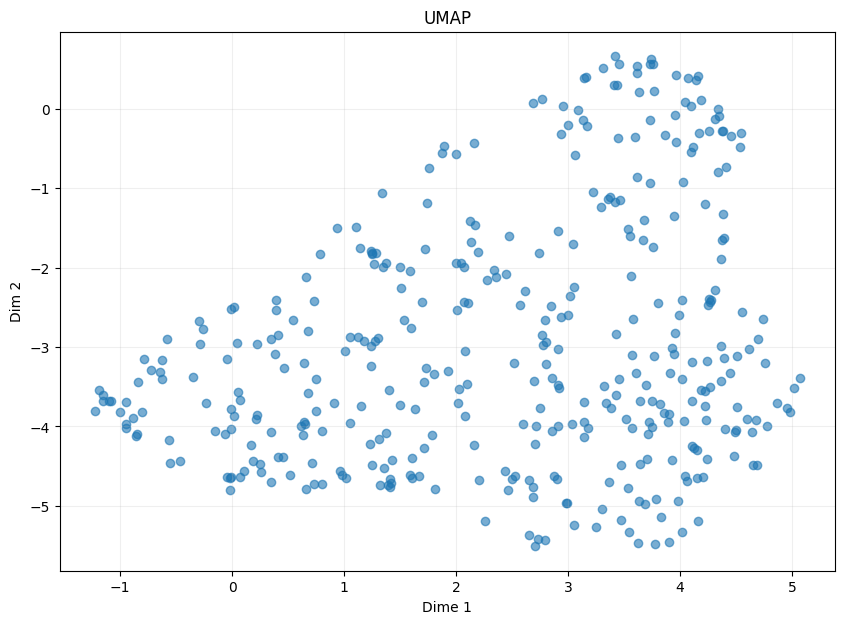

In [ ]:
plt.figure(figsize=(10, 7))
plt.scatter(
    umap_embeddings[:, 0],
    umap_embeddings[:, 1],
    alpha=0.6
)

plt.title("UMAP")
plt.xlabel("Dime 1")
plt.ylabel("Dim 2")
plt.grid(alpha=0.2)
plt.show()

# RAGAS (3 балла)

RAGAS - это система, созданная для автоматической оценки эффективности модели RAG. Она представляет собой комплексный инструмент, способный оценить как качество извлечения информации, так и качество созданного текста. Это достигается благодаря использованию различных метрик, которые анализируют разные аспекты ответов, сгенерированных языковой моделью.



## Метрики оценки в RAGAS

### Faithfulness
Оценивает, насколько ответы языковой модели верно передают информацию, содержащуюся в источниках данных. Это критически важно, чтобы гарантировать, что модель не искажает или не меняет информацию при её интерпретации.

---

$
Faithfulness = \frac{\text{|Number of claims that can be inferred from given context|}}{\text{|Total number of claims in the generated answer|}}
$

### Answer Relevancy
Демонстрирует, насколько ответы соответствуют заданным вопросам. Это важный аспект, так как даже правильный ответ с технической точки зрения может быть ненужным, если он не отвечает на конкретный вопрос пользователя.

---

$\text{answer relevancy} = \frac{1}{N} \sum_{i=1}^{N} cos(E_{g_i}, E_o)$

$\text{answer relevancy} = \frac{1}{N} \sum_{i=1}^{N} \frac{E_{g_i} \cdot E_o}{\|E_{g_i}\|\|E_o\|}$

Где:

* $E_{g_i}$ - это эмбеддинг сгенерированного ответа $i$

* $E_o$ - это эмбеддинг исходного вопроса.

* $N$ - это количество сгенерированных вопросов, которое по умолчанию равно 3.

### Context Recall и Context Precision
Эти метрики измеряют эффективность модели в учете контекста вопроса для формирования ответа. "Context Recall" оценивает количество использованной информации из контекста в ответе, в то время как "Context Precision" оценивает точность и релевантность использования контекстной информации.

---

* $ \text{context recall} = \frac{\text{|GT sentences that can be attributed to context|}}{\text{|Number of sentences in GT|}} $
* $Context Precision@k = \frac{\sum \text{precision@k}}{\text{total number of relevant items in the top K results}}$
  * $Precision@k = \frac{\text {true positives@k}}{\text{(true positives@k + false positives@k)}}$

### Answer Semantic Similarity
Оценивает степень семантической близости между ответом модели и эталонным ответом. Это позволяет определить, насколько естественно и точно модель способна воссоздавать человеческий язык.

### Answer Correctness
Оценка корректности ответа. Это последний шаг в проверке, чтобы убедиться, предоставляет ли модель точную и достоверную информацию в своем ответе.

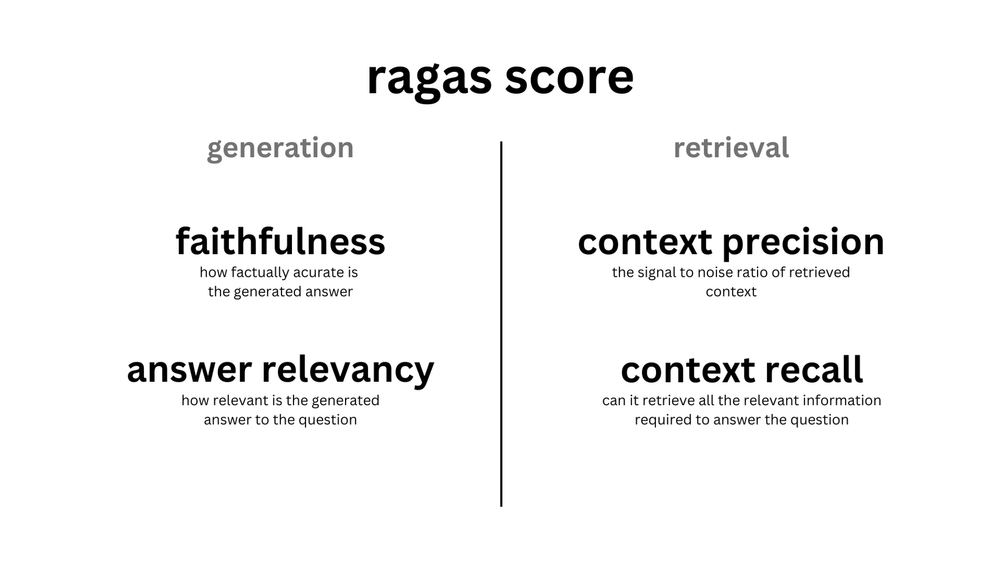

В этом задании вам нужно реализовать метрику answer_relevancy в коде. Опционально за допбаллы можно реализовать другие метрики.

Для этого датасет нужно привести к виду, в котором будут следующие поля:

### 1. question
- Смысл: Эта колонка содержит вопросы, на которые нужно найти ответы. В контексте задач QA, это основная информация, которую модель должна обработать для генерации ответа.
- Пример: "Каковы преимущества RAG?"

### 2. ground_truths
- Смысл: В этой колонке находятся правильные ответы на соответствующие вопросы. Это может использоваться для оценки производительности модели, так как позволяет сравнить сгенерированные ответы с эталонными.
- Пример: "RAG улучшает качество генерации, используя внешние источники информации."

### 3. answer
- Смысл: Эта колонка содержит ответы, которые генерирует модель на основе заданных вопросов. Это может быть результат работы модели, которую вы тестируете или обучаете.
- Пример: "RAG позволяет моделям извлекать информацию из внешних источников, что улучшает их способность отвечать на сложные вопросы."

### 4. contexts
- Смысл: Эта колонка предоставляет контекст или дополнительную информацию, которая может быть полезна для понимания вопроса или для формирования ответа. Это может быть текст, из которого был извлечен ответ, или другие релевантные документы.
- Пример: "RAG (Retrieval-Augmented Generation) — это метод, который использует внешние базы данных для получения информации при генерации текста."

HINT: Поле question можно тоже сгенерировать. Например, можно попросить модель задать вопрос по описанию изображения.

HINT: Для answer_relevancy нужны не все поля

HINT: Инференс такого эксперимента может быть долгим. План минимум: возьмите 100 случайных сэмплов.

Сгенерируем 100 вопросов и ответим на них. Ответы вручную

In [ ]:
questions = [
    'What are the main landmarks to visit in Vladimir?',
    'Which churches can visitors see in Vladimir?',
    'Which museums are located in Vladimir?',
    'Which monasteries are listed as places to visit in Vladimir?',
    'What religious cathedrals are listed in Vladimir?',
    "Where can visitors learn about Vladimir's history?",
    'Which cultural venues can visitors attend in Vladimir?',
    'Where can visitors see exhibitions in Vladimir?',
    'Which memorials can visitors see in Vladimir?',
    'Which historic gates or defensive structures are worth visiting in Vladimir?',
    'Which religious sites in Vladimir are dedicated to the Virgin Mary?',
    'What places in Vladimir are associated with science and education?',
    'Which monuments in Vladimir commemorate notable people?',
    'Where can visitors see art in Vladimir?',
    'Which parks or green spaces are listed in Vladimir?',
    'What unusual museums can visitors explore in Vladimir?',
    'Which churches in Vladimir are connected with monasteries?',
    'Where can visitors see military history in Vladimir?',
    'Which buildings in Vladimir are associated with historic civic administration?',
    'What memorial sites in Vladimir relate to the Second World War?',
    'Which religious buildings in Vladimir are not Orthodox churches?',
    'Where can visitors attend music or concerts in Vladimir?',
    'Which attractions in Vladimir are connected with local heritage?',
    'What towers or tower-like landmarks can visitors see in Vladimir?',
    'Which religious chapels are listed in Vladimir?',
    'What are the main historic landmarks to visit in Yekaterinburg?',
    'Which churches and cathedrals can visitors see in Yekaterinburg?',
    'Which museums can visitors explore in Yekaterinburg?',
    'Which historic estates are open as attractions in Yekaterinburg?',
    'What theatres are listed in Yekaterinburg?',
    'Which memorials can visitors see in Yekaterinburg?',
    'Where can visitors learn about Ural literature in Yekaterinburg?',
    'Which historic houses can visitors visit in Yekaterinburg?',
    'Which parks or gardens are listed in Yekaterinburg?',
    'What religious monasteries can visitors see in Yekaterinburg?',
    "Which towers are listed among Yekaterinburg's attractions?",
    'Where can visitors explore art in Yekaterinburg?',
    'Which music venues can visitors attend in Yekaterinburg?',
    'What historic squares are listed in Yekaterinburg?',
    'Which bridges can visitors see in Yekaterinburg?',
    'Where can visitors learn about the history of transport and technology in Yekaterinburg?',
    'Which educational institutions are notable listed sites in Yekaterinburg?',
    "Which buildings in Yekaterinburg are associated with the city's industrial history?",
    'What cultural attractions in Yekaterinburg are suitable for families?',
    'Which churches in Yekaterinburg are named after saints?',
    'Where can visitors see architecture from the Soviet period in Yekaterinburg?',
    'Which streets in Yekaterinburg are included as attractions?',
    'What stadium or sports venue is listed in Yekaterinburg?',
    'Which museums in Yekaterinburg focus on local or regional history?',
    'What notable residential or commercial buildings can visitors see in Yekaterinburg?',
    'What are the main landmarks to visit in Nizhny Novgorod?',
    'Which churches and cathedrals can visitors see in Nizhny Novgorod?',
    'Which monasteries are listed in Nizhny Novgorod?',
    'Which museums can visitors explore in Nizhny Novgorod?',
    'What towers can visitors see at the Nizhny Novgorod Kremlin?',
    'Which parks are listed as places to visit in Nizhny Novgorod?',
    'Which theatres can visitors attend in Nizhny Novgorod?',
    'Where can visitors learn about Maxim Gorky in Nizhny Novgorod?',
    'Which historic houses can visitors see in Nizhny Novgorod?',
    'Which religious sites in Nizhny Novgorod are dedicated to the Transfiguration?',
    'What monuments commemorate important historical figures in Nizhny Novgorod?',
    'Which memorials in Nizhny Novgorod commemorate military history?',
    'Where can visitors see historic civic or financial architecture in Nizhny Novgorod?',
    'Which religious sites in Nizhny Novgorod are dedicated to Alexander Nevsky?',
    'What steps or stairways are notable attractions in Nizhny Novgorod?',
    'Which cultural or educational institutions are listed in Nizhny Novgorod?',
    'Where can visitors explore local science and technology in Nizhny Novgorod?',
    'Which religious buildings in Nizhny Novgorod are associated with the Nativity?',
    'What historic commercial buildings can visitors see in Nizhny Novgorod?',
    'Which towers in Nizhny Novgorod have names connected with defensive architecture?',
    'Where can visitors see religious architecture beyond Orthodox churches in Nizhny Novgorod?',
    'Which estates are listed as attractions in Nizhny Novgorod?',
    'Which historic religious cathedrals can visitors visit in Nizhny Novgorod?',
    'What attractions in Nizhny Novgorod relate to national unity and civic history?',
    'Which churches in Nizhny Novgorod are named after major Christian festivals?',
    'What are the main historic attractions to visit in Yaroslavl?',
    'Which churches can visitors see in Yaroslavl?',
    'Which monasteries are listed as attractions in Yaroslavl?',
    'Which museums can visitors explore in Yaroslavl?',
    'Which parks or gardens can visitors visit in Yaroslavl?',
    'What theatres are listed in Yaroslavl?',
    'Which cathedrals can visitors see in Yaroslavl?',
    "Where can visitors learn about Yaroslavl's history?",
    'Which museums in Yaroslavl focus on notable writers or artists?',
    'Which religious buildings in Yaroslavl are dedicated to the Nativity?',
    'What monuments can visitors see in Yaroslavl?',
    "Which towers are listed among Yaroslavl's attractions?",
    'Where can visitors see religious architecture near the Volga in Yaroslavl?',
    'Which cultural museums can visitors explore in Yaroslavl?',
    'What memorial sites in Yaroslavl commemorate military history?',
    'Which historic buildings in Yaroslavl are associated with regional government?',
    'Which religious chapels are listed in Yaroslavl?',
    'What archaeological or ancient sites can visitors explore in Yaroslavl?',
    'Which bridges or waterfront landmarks are listed in Yaroslavl?',
    'Which churches in Yaroslavl are dedicated to Archangel Michael or other saints?',
    'Where can visitors see art collections in Yaroslavl?',
    'Which religious sites in Yaroslavl are associated with the Holy Cross?',
    'What attractions in Yaroslavl are suitable for families?',
    'Which mosques or non-Orthodox religious sites are listed in Yaroslavl?',
    "Where can visitors explore historic religious architecture in Yaroslavl's Tolchkovo area?"
]

In [ ]:
ground_truth = [
    'The dataset lists the Golden Gate, the Assumption Cathedral, the St. Demetrius Cathedral, and the former water tower.',
    'The listed churches include the Trinity Church, the Church of St. Nikita the Martyr, the Church of the Nativity of Christ, the Church of St. Alexander Nevsky, and the Church of the Kazan Icon of the Mother of God.',
    'Visitors can find the Museum of Crystal and Glass of the 18th–21st Centuries, the Spoon Museum, the Nature Museum, the Museum of Science and Man Eureka, the Museum of Unreal Stories, and the Historical Museum.',
    'The dataset includes the Nativity Monastery and the Dormition Knyaginin Monastery.',
    'The listed cathedrals are the Assumption Cathedral and St. Demetrius Cathedral.',
    'The Historical Museum, the Vladimir-Suzdal Museum-Reserve central office, the Old Vladimir exhibition, and the military-historical exhibition at the Golden Gate are listed.',
    'The Vladimir Academic Regional Drama Theatre, the Vladimir Regional Puppet Theatre, the Folklore Theatre Razgulyai, and the Classical Music Center are listed.',
    'The Exhibition Hall, the Gallery of the Vladimir School of Painting, the Crystal and Glass Museum, and the Museum of Nature are listed.',
    'The Eternal Flame, the memorial to those who died in the Second World War, the memorial to internationalist soldiers, and the memorial to Vladimir railway workers are listed.',
    'The Golden Gate, the Ivanovo Rampart, the Kozlov Rampart, and the ancient defensive earth rampart of Vladimir are listed.',
    'The Assumption Cathedral, the Church of the Kazan Icon of the Mother of God, and the chapel honoring the Iveron Icon of the Mother of God are listed.',
    'The Vladimir Aviation Mechanical College, the Vladimir Theological Seminary, the Vladimir Planetarium, and the Eureka Museum of Science and Man are listed.',
    'The Gogol Monument and the monument to Prince Vladimir and Saint Theodore are listed.',
    'The Gallery of the Vladimir School of Painting, the Exhibition Hall, and the Crystal and Glass Museum are listed.',
    'The Druzhba Forest Park and the Library Lawn are listed.',
    'The Spoon Museum, the Museum of Unreal Stories, and the Eureka Museum of Science and Man are listed.',
    'The Nativity Monastery and the Dormition Knyaginin Monastery are listed religious complexes.',
    'The military-historical exhibition at the Golden Gate and the memorial to internationalist soldiers are listed.',
    'The Chambers building, the City Duma building, and the former Public Offices building are listed.',
    'The Eternal Flame, the memorial to those who died in the Second World War, and the memorial to Vladimir railway workers are listed.',
    'The Armenian Church of Vladimir, the Roman Catholic Church of the Holy Rosary of the Blessed Virgin Mary, and the Evangelical Christian Church Chapel near Golgotha are listed.',
    'The S. I. Taneyev Concert Hall, the Classical Music Center, and the Virtual Concert Hall are listed.',
    'The Old Pharmacy, the Museum of Unreal Stories, the Old Vladimir exhibition, and the Vladimir-Suzdal Museum-Reserve are listed.',
    'The former water tower and the model of the Soyuz-TM launch vehicle are listed.',
    'The Gate Church of St. Prince Alexander Nevsky and the chapel honoring the Iveron Icon of the Mother of God are listed.',
    'The dataset lists the Sevastyanov House, the Rastorguyev-Kharitonov Estate, the White Tower, and the Stone Bridge.',
    'The listed religious sites include the Alexander Nevsky Cathedral, St. John the Baptist Cathedral, the Holy Trinity Cathedral, the Ascension Church, the Church on the Blood, and the Holy Cross Church.',
    "The Yekaterinburg Museum of Fine Arts, the Museum of the History of Yekaterinburg, the Sverdlovsk Regional Museum of Local Lore, the Museum of Dolls and Children's Books Wonderland, and the Ernst Neizvestny Art Museum are listed.",
    'The dataset lists the Rastorguyev-Kharitonov Estate, the Zheleznov Estate, the Tarasov Estate, and the estate of Captain Pereyaslavtsev.',
    'The Puppet Theatre, the Musical Comedy Theatre, and the Opera and Ballet Theatre are listed.',
    'The memorial to the Ural Communards, the monument to the tank volunteers, and monuments to Yakov Sverdlov, Lenin, and Sergo Ordzhonikidze are listed.',
    'The Museum of the Literary Life of the Urals in the 19th Century and the exhibition on the Literary Life of the Urals in the 20th Century are listed.',
    'The Bazhov House Museum, the D. N. Mamin-Sibiryak House Museum, the F. M. Reshetnikov House Museum, and the Metenkov House are listed.',
    'Kharitonov Garden is listed.',
    'The Novo-Tikhvin Monastery is listed.',
    'The White Tower and the Water Tower are listed.',
    'The Yekaterinburg Museum of Fine Arts, the Museum of Fine Arts, and the Ernst Neizvestny Art Museum are listed.',
    'The Sverdlovsk State Academic Philharmonic and the Ural State Conservatory are listed.',
    'The Square of the First Five-Year Plan and 1905 Square are listed.',
    "The Stone Bridge and the Tsar's Bridge are listed.",
    'The Museum of the History, Science and Technology of the Sverdlovsk Railway and the Ural Geological Museum are listed.',
    'Gymnasium No. 9, the Ural State Conservatory, and the Ural State Technical University are listed.',
    'The Yekaterinburg Plant, the House of Industry, and the Ural Turbine Plant are listed.',
    "The Puppet Theatre and the Museum of Dolls and Children's Books Wonderland are listed.",
    'The Alexander Nevsky Cathedral, St. John the Baptist Cathedral, and St. Nicholas Church are listed.',
    'The Second House of Soviets, the Chekist Town, and the House of Industry are listed.',
    'Dobrolyubov Street, February Revolution Street, and Chernyshevsky Street are listed.',
    'The Central Stadium is listed.',
    'The Museum of the History of Yekaterinburg and the Sverdlovsk Regional Museum of Local Lore are listed.',
    'The Sevastyanov House, the House of Offices, the Chuvildin Merchant House, and the Brevnov House are listed.',
    'The dataset lists the Nizhny Novgorod Kremlin, the Chkalov Staircase, the Alexander Nevsky Cathedral, and the State Bank building.',
    'The listed sites include the Annunciation Cathedral, the Transfiguration Cathedral, the Cathedral of the Archangel Michael, the Nativity Church, and the Church of the Resurrection of Christ.',
    'The Annunciation Monastery, the Exaltation of the Cross Monastery, and the Pechersky Ascension Monastery are listed.',
    'The Nizhny Novgorod State Art Museum, the Museum of Science Nizhny Novgorod Radio Laboratory, the Gorky Apartment Museum, and the Dobrolyubov House Museum are listed.',
    'The listed towers include the Dmitrievskaya, Borisoglebskaya, Georgievskaya, Ivanovskaya, Zachatievskaya, Koromyslova, Kladovaya, Nikolskaya, Powder, Northern, and Taynitskaya towers.',
    'The Avtozavodsky Park of Culture and Recreation, Kulibin Park, Pushkin Park, and Sormovo Park are listed.',
    'The Nizhny Novgorod State Academic Drama Theatre named after Gorky and the Opera and Ballet Theatre are listed.',
    'The Gorky Apartment Museum and the Kashirin House are listed.',
    "The houses of A. I. Frolov, A. K. Fomin, V. I. Smirnov, and the Vinogradov family are listed, along with the Kashirin House and Peter the Great's House.",
    'The Transfiguration Church and the Transfiguration Cathedral are listed.',
    'The obelisk to Minin and Pozharsky, the monument to Lenin, and the monument to Maxim Gorky are listed.',
    "The monument to the heroes of the Volga Military Flotilla and the memorial Gor'kovites to the Front are listed.",
    "The State Bank building, the Volga-Kama Bank building, the Governor's Palace, and the City Administration building are listed.",
    'The Alexander Nevsky Cathedral and the Church of Alexander Nevsky in Sormovo are listed.',
    'The Chkalov Staircase is listed.',
    'The Nizhny Novgorod State Conservatory named after M. I. Glinka, the River School, and Lyceum No. 82 are listed.',
    'The Museum of Science Nizhny Novgorod Radio Laboratory is listed.',
    'The Nativity Church and the Church of the Nativity of the Mother of God are listed.',
    'The Blinov Passage, the trading wing of O. N. Kameneva, and the income houses of B. N. Yusupov and P. E. Kubareva are listed.',
    'The Powder Tower, Northern Tower, Watchtower, Pantry Tower, and Secret Tower are listed.',
    'The Nizhny Novgorod Cathedral Mosque is listed.',
    'The Vyakhirev Estate, the Dobrolyubov Estate, the Kirshbaum Estate, and the Rukavishnikov Estate are listed.',
    'The Annunciation Cathedral, the Exaltation of the Cross Cathedral, the Transfiguration Cathedral, and the Alexander Nevsky Cathedral are listed.',
    'The Nizhny Novgorod Kremlin, the obelisk to Minin and Pozharsky, and the exhibition The Feat of National Unity are listed.',
    'The Church of the Resurrection of Christ, the Nativity Church, and the Transfiguration Church are listed.',
    'The dataset lists the historic centre of Yaroslavl, the Spaso-Preobrazhensky Monastery, the Church of Elijah the Prophet, and the Millennium of Yaroslavl Monument.',
    'The listed churches include the Church of Elijah the Prophet, the Church of the Epiphany, the Church of the Annunciation, the Church of the Ascension, and the Church of John the Baptist in Tolchkovo.',
    'The Kazan Convent, the Kirillo-Afanasiyev Monastery, the Spaso-Preobrazhensky Monastery, the Tolga Monastery, and the Nikolo-Skovorodsky Monastery are listed.',
    'The Yaroslavl Museum-Reserve, the Museum of Military Glory, the Museum of Foreign Art, the Museum of the History of Yaroslavl, and the Museum of Ancient Russian Art are listed.',
    'The Millennium of Yaroslavl Park, Strelka Park, Demidov Garden, and Petropavlovsky Park are listed.',
    'The Fyodor Volkov Russian State Academic Drama Theatre, the Puppet Theatre, and the Yaroslavl Youth Theatre named after V. S. Rozov are listed.',
    'The Assumption Cathedral, the Transfiguration Cathedral, and the Feodorovsky Cathedral are listed.',
    'The Museum of the History of Yaroslavl, the Yaroslavl Museum-Reserve, and the historic centre of Yaroslavl are listed.',
    'The Maxim Bogdanovich Memorial House Museum and the Museum of Music and Time are listed.',
    'The Church of the Nativity of Christ and the Church of the Nativity of the Lord are listed.',
    'The Millennium of Yaroslavl Monument, the monument to Nikolay Nekrasov, the monument to Fyodor Volkov, and the monument to Leonid Trefolev are listed.',
    'The Epiphany Tower, the Vlasyevskaya (Znamenskaya) Tower, and the Volga Tower are listed.',
    'The Church of St. Nicholas the Wonderworker in Melenki and the Church of St. John Chrysostom in Korovniki are listed.',
    'The Museum of Music and Time, the Museum of Entertaining Sciences of Einstein, and the Museum of Foreign Art are listed.',
    'The Museum of Military Glory, the Eternal Flame, and the Military Memorial Cemetery are listed.',
    "The Governor's House and the Gostiny Dvor are listed.",
    'The Alexander Nevsky Chapel and the Chapel of Our Lady of Kazan are listed.',
    'The Timerovo Archaeological Complex and the Mikhailovskie Burial Mounds are listed.',
    'The Volga Gates Bridge and the gazebo on the Volga Embankment are listed.',
    'The Church of Archangel Michael, the Church of St. Nicholas the Wonderworker, and the Church of St. Demetrius of Thessaloniki are listed.',
    "The Yaroslavl Art Museum, the Governor's House art museum, and the Museum of Ancient Russian Art are listed.",
    'The Parish of the Exaltation of the Holy Cross is listed.',
    'The Yaroslavl Zoo, the Puppet Theatre, and the Museum of Entertaining Sciences of Einstein are listed.',
    'The Yaroslavl Cathedral Mosque is listed.',
    'The Church of John the Baptist in Tolchkovo is listed.'
]

In [ ]:
def data_preprocess(questions, k=3, rerank_k=3):
    answers = []
    contexts = []

    for question in tqdm(questions):
        retrieved_docs = KNOWLEDGE_VECTOR_DATABASE.similarity_search(
            query=question,
            k=k
        )

        documents = [[doc.page_content for doc in retrieved_docs]]
        documents_ids = [[str(i) for i in range(len(retrieved_docs))]]

        queries_embeddings = reranker_model.encode(
            [question],
            is_query=True
        )

        documents_embeddings = reranker_model.encode(
            documents,
            is_query=False
        )

        reranked_documents = rank.rerank(
            documents_ids=documents_ids,
            queries_embeddings=queries_embeddings,
            documents_embeddings=documents_embeddings
        )

        reranked_docs = [
            retrieved_docs[int(result["id"])]
            for result in reranked_documents[0][:rerank_k]
        ]

        context = "\nExtracted documents:\n"

        for i, doc in enumerate(reranked_docs):
            context += f"""
                Document {i}:
                Name: {doc.metadata.get('Name', 'Unknown')}
                City: {doc.metadata.get('city', 'Unknown')}
                Latitude: {doc.metadata.get('Lat', 'Unknown')}
                Longitude: {doc.metadata.get('Lon', 'Unknown')}
                Description: {doc.page_content}
            """

        final_prompt = RAG_PROMPT_TEMPLATE.format(
            question=question,
            context=context
        )

        answer = READER_LLM(final_prompt)[0]["generated_text"]

        answers.append(answer)

        contexts.append([
            f"""
            Name: {doc.metadata.get('Name', 'Unknown')}
            City: {doc.metadata.get('city', 'Unknown')}
            Latitude: {doc.metadata.get('Lat', 'Unknown')}
            Longitude: {doc.metadata.get('Lon', 'Unknown')}
            Description: {doc.page_content}
            """
            for doc in reranked_docs
        ])

    return answers, contexts

In [ ]:
answers, contexts = data_preprocess(questions)

  0%|          | 0/100 [00:00<?, ?it/s]

Both `max_new_tokens` (=1000) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1000) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1000) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1000) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


In [ ]:
def llm_judge(prompt):
    result = READER_LLM(prompt, do_sample=False, max_new_tokens=500)[0]["generated_text"]
    return result.strip()

In [ ]:
def answer_relevancy(question, answer, n=3):
    prompt = f"""
    You are an expert evaluator of Retrieval-Augmented Generation (RAG) systems.

    Generated answer:
    {answer}

    Task:
    Generate {n} different questions that could be correctly
    and meaningfully answered using the information in the generated answer.

    Requirements:
    - Each question must be relevant to the content of the answer.
    - Do not introduce information that is not present in the answer.
    - Write each question on a separate line.
    - Do not include numbering or explanations.
    """

    result = llm_judge(prompt)

    generated_questions = [line.strip().lstrip("0123456789.-) ") for line in result.splitlines() if line.strip()]

    generated_questions = generated_questions[:n]

    if not generated_questions:
        return np.nan

    question_embedding = embedding_model.embed_query(question)

    generated_embeddings = embedding_model.embed_documents(generated_questions)

    similarities = []

    for embedding in generated_embeddings:
        similarity = np.dot(question_embedding, embedding) / (np.linalg.norm(question_embedding) * np.linalg.norm(embedding))
        similarities.append(similarity)

    return float(np.mean(similarities))

# Протестируйте ваш RAG (3 балла)

In [ ]:
answer_relevancy_results = []

for i in tqdm(range(len(questions))):
    score = answer_relevancy(question=questions[i], answer=answers[i])

    answer_relevancy_results.append({
        "Question": questions[i],
        "Answer": answers[i],
        "Answer Relevancy": score
    })

answer_relevancy_df = pd.DataFrame(answer_relevancy_results)

display(answer_relevancy_df)

  0%|          | 0/100 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Passing `generation_config` together with generation-related arguments=({'do_sample', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=500) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=20) seem to have been set. `max_new_token

,Question,Answer,Answer Relevancy
0,What are the main landmarks to visit in Vladimir?,Name: Центр классической музыки\nCity: Владими...,0.345171
1,Which churches can visitors see in Vladimir?,Name of the attractions: \n1. Спасо-преображен...,0.377116
2,Which museums are located in Vladimir?,Name of the attraction: Центр классической муз...,0.450123
3,Which monasteries are listed as places to visi...,Name: Центр классической музыки\nCity: Владими...,0.255388
4,What religious cathedrals are listed in Vladimir?,Name: Центр классической музыки\nCity: Владими...,0.509154
...,...,...,...
95,Where can visitors see art collections in Yaro...,Name: Музей зарубежного искусства\nCity: Яросл...,0.314194
96,Which religious sites in Yaroslavl are associa...,Name: Церкви Вознесения Господня\nCity: Яросла...,0.333592
97,What attractions in Yaroslavl are suitable for...,Name of the attraction: Yaroslavl Museum of Cu...,0.604450
98,Which mosques or non-Orthodox religious sites ...,Name: None\n\nCity: Yaroslavl\nLatitude: 55.55...,0.845373


In [ ]:
mean_answer_relevancy = answer_relevancy_df["Answer Relevancy"].mean()
print(f"Answer Relevancy: {mean_answer_relevancy:.4f}")

Answer Relevancy: 0.4372


# Дополнительная часть (+3 балла)

Реализуйте одну из метрик retrieval-части на выбор.

Для того, чтобы понять model as a judge подход из RAGAS, советуем посетить [этот кукбук](https://huggingface.co/learn/cookbook/en/rag_evaluation)

In [ ]:
def context_recall(context, ground_truth):
    prompt = f"""
        You are an expert evaluator of Retrieval-Augmented Generation systems.

        Reference answer:
        {ground_truth}

        Retrieved context:
        {context}

        Task:
        1. Break the reference answer into individual factual claims.
        2. Check which claims are supported by the retrieved context.
        3. Do not use external knowledge.
        4. Count only explicitly stated or clearly implied information.

        Return strictly in this format:
        SUPPORTED: number
        TOTAL: number

        Do not provide explanations.
    """

    result = llm_judge(prompt)

    try:
        supported = int(result.split("SUPPORTED:")[1].splitlines()[0].strip())
        total = int(result.split("TOTAL:")[1].splitlines()[0].strip())

        return supported / total if total > 0 else np.nan

    except (ValueError, IndexError):
        return np.nan

In [ ]:
context_recall_results = []

for i in tqdm(range(len(questions))):
    full_context = "\n\n".join(contexts[i])

    score = context_recall(context=full_context, ground_truth=ground_truth[i])

    context_recall_results.append({
        "Question": questions[i],
        "Ground Truth": ground_truth[i],
        "Context Recall": score
    })

context_recall_df = pd.DataFrame(context_recall_results)

display(context_recall_df)

  0%|          | 0/100 [00:00<?, ?it/s]

Both `max_new_tokens` (=500) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both

,Question,Ground Truth,Context Recall
0,What are the main landmarks to visit in Vladimir?,"The dataset lists the Golden Gate, the Assumpt...",1.0
1,Which churches can visitors see in Vladimir?,The listed churches include the Trinity Church...,NaN
2,Which museums are located in Vladimir?,Visitors can find the Museum of Crystal and Gl...,NaN
3,Which monasteries are listed as places to visi...,The dataset includes the Nativity Monastery an...,NaN
4,What religious cathedrals are listed in Vladimir?,The listed cathedrals are the Assumption Cathe...,1.0
...,...,...,...
95,Where can visitors see art collections in Yaro...,"The Yaroslavl Art Museum, the Governor's House...",1.0
96,Which religious sites in Yaroslavl are associa...,The Parish of the Exaltation of the Holy Cross...,1.0
97,What attractions in Yaroslavl are suitable for...,"The Yaroslavl Zoo, the Puppet Theatre, and the...",1.0
98,Which mosques or non-Orthodox religious sites ...,The Yaroslavl Cathedral Mosque is listed.,1.0


In [ ]:
mean_context_recall = context_recall_df["Context Recall"].mean()
print(f"Context Recall: {mean_context_recall:.4f}")

Context Recall: 0.9879
